In [31]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [32]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [33]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


idealspecies_withsols = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

realspecies_withsols = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [34]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.25
N_masspercent_lodders09  = 0.08

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=1):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.linspace(0.001, 0.1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -3)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

## Oxygen fugacity



In [35]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [28]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyfO2_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyfO2_withsol = model_ideal_varyfO2_withsol.output

# Write the complete solution to Excel
output_ideal_varyfO2_withsol.to_excel("YEYERIDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyfO2_withsol.to_pickle("YEYERIDEAL")

[11:49:34 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[11:49:34 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:49:34 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:49:34 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[11:49:34 - atmodeller.cl

In [29]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyfO2_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
)
A_FINAL_TEST_FO2_REALS = model_real_varyfO2_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_FO2_REALS.to_excel("YEYERREAL")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_FO2_REALS.to_pickle("YEYERREAL")

[11:49:35 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:49:35 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:49:35 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:49:35 - atmodeller.classes             - IN

In [24]:

output_df = A_FINAL_TEST_FO2_REALS.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

dissolved_ppmwN2 = output_df["N2_g"]["atmosphere_ppmw"]
dissolved_wtpN2 = dissolved_ppmwN2 * 1e-4  # wt.%

dissolved_ppmwH3N = output_df["H3N_g"]["atmosphere_ppmw"]
dissolved_wtpH3N = dissolved_ppmwH3N * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["atmosphere_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["atmosphere_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%

dissolved_ppmwCO = output_df["CO_g"]["atmosphere_ppmw"]
dissolved_wtpCO = dissolved_ppmwCO * 1e-4  # wt.%

dissolved_ppmwH2 = output_df["H2_g"]["atmosphere_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["atmosphere_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%



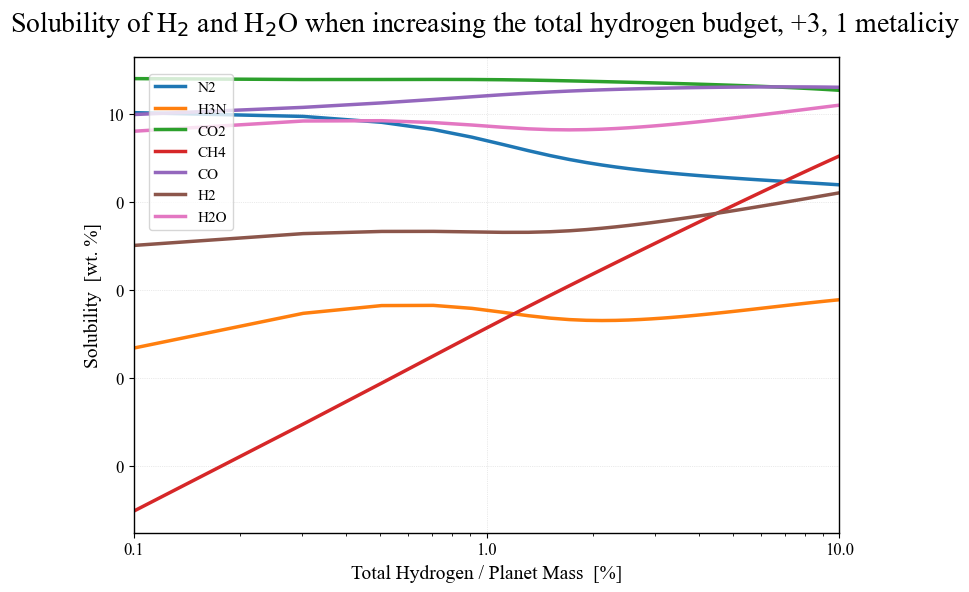

In [25]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.cm import get_cmap
import numpy as np
from matplotlib import colormaps

def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 14
    plt.rcParams["xtick.labelsize"]    = 12
    plt.rcParams["ytick.labelsize"]    = 12
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.5
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)


set_master_nature_style()

fig, ax = plt.subplots(figsize=(8, 6))

# ------------------------------------------
# Plot solubility curves (wt.%)
# ------------------------------------------
ax.plot(H_mass_fraction*100, dissolved_wtpN2,  lw=2.5, label="N2")
ax.plot(H_mass_fraction*100, dissolved_wtpH3N, lw=2.5, label="H3N")
ax.plot(H_mass_fraction*100, dissolved_wtpCO2,  lw=2.5, label="CO2")
ax.plot(H_mass_fraction*100, dissolved_wtpCH4, lw=2.5, label="CH4")
ax.plot(H_mass_fraction*100, dissolved_wtpCO,  lw=2.5, label="CO")
ax.plot(H_mass_fraction*100, dissolved_wtpH2, lw=2.5, label="H2")
ax.plot(H_mass_fraction*100, dissolved_wtpH2O,  lw=2.5, label="H2O")
# ------------------------------------------
# Y-axis: log scale, plain-number ticks like 0.1, 1, 10
# ------------------------------------------
ax.set_yscale("log")

# major ticks at decades only
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))

# numeric formatting (0.1, 1, 10 — NOT 10⁻¹)
y_formatter = ticker.ScalarFormatter()
y_formatter.set_scientific(False)
ax.yaxis.set_major_formatter(y_formatter)

# minor ticks between decades, unlabeled
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

# ------------------------------------------
# X-axis: use same logic as your pressure plot
# min → 1 → max
# ------------------------------------------
xmin = min(H_mass_fraction)*100
xmax = max(H_mass_fraction)*100
x_ticks = [xmin, 1, xmax]

ax.set_xscale("log")
ax.set_xlim(xmin, xmax)
ax.xaxis.set_major_locator(ticker.FixedLocator(x_ticks))

x_formatter = ticker.ScalarFormatter()
x_formatter.set_scientific(False)
ax.xaxis.set_major_formatter(x_formatter)

ax.set_xlabel("Total Hydrogen / Planet Mass  [%]")
ax.set_ylabel("Solubility  [wt. %]")

fig.suptitle("Solubility of H$_2$ and H$_2$O when increasing the total hydrogen budget, +3, 1 metaliciy",
             fontsize=20, ha="center", x=0.52, y=0.98)

ax.legend(
    frameon=True,
    loc="upper left",
    bbox_to_anchor=(0.01, 0.98)
)

plt.tight_layout()
plt.show()


## Vary Planetary Mass

Planet mass varies from 4 to 9 MEarth, surface radius is fixed at 1.76 REarth

In [36]:

def radius(mass):
    rad = 1.02*(mass**0.252)
    return rad
# For simulations with varying planet mass:

planet_mass_Earths = np.linspace(4, 20, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24

planet_radii_Earths = radius(planet_mass_Earths)
planet_radius = planet_radii_Earths * 6371000

h_kg = 0.01 * planet_mass
mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [37]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [38]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("A_FINAL_TEST_MASS_IDEAL_LAST")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("A_FINAL_TEST_MASS_IDEAL_LAST")

[19:06:01 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[19:06:01 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:06:01 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[19:06:01 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[19:06:04 - atmodeller.cl

In [39]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
A_FINAL_TEST_MASS_REAL = model_real_varyMp_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_MASS_REAL.to_excel("A_FINAL_TEST_MASS_REAL_LAST")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_MASS_REAL.to_pickle("A_FINAL_TEST_MASS_REAL_LAST")

[19:06:05 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[19:06:05 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:06:05 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[19:06:05 - atmodeller.classes             - IN

In [40]:

output_df = A_FINAL_TEST_MASS_REAL.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

fugacityH2 = output_df["H2_g"]["fugacity"]
fugacityH2O = output_df["H2O_g"]["fugacity"]
fugacityCO2 = output_df["CO2_g"]["fugacity"]
fugacityCH4 = output_df["CH4_g"]["fugacity"]

element_H = output_df["element_H"]["atmosphere_ppmw"] * 10**-4
element_O = output_df["element_O"]["atmosphere_ppmw"] * 10**-4
element_C = output_df["element_C"]["atmosphere_ppmw"] * 10**-4
element_N = output_df["element_N"]["atmosphere_ppmw"] * 10**-4

ratio_H_C = element_H / element_C
ratio_H_O = element_H / element_O
ratio_C_O = element_C / element_O

dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["dissolved_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["dissolved_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%



atm_ppmwH2 = output_df["H2_g"]["atmosphere_ppmw"]
atm_wtpH2 = atm_ppmwH2 * 1e-4  # wt.%

atm_ppmwH2O = output_df["H2O_g"]["atmosphere_ppmw"]
atm_wtpH2O = atm_ppmwH2O * 1e-4  # wt.%

atm_ppmwCO2 = output_df["CO2_g"]["atmosphere_ppmw"]
atm_wtpCO2 = atm_ppmwCO2 * 1e-4  # wt.%

atm_ppmwCH4 = output_df["CH4_g"]["atmosphere_ppmw"]
atm_wtpCH4 = atm_ppmwCH4 * 1e-4  # wt.%

RATIO_H2_CO2 = atm_wtpH2 / atm_wtpCO2
RATIO_H2O_CH4 = atm_wtpH2O / atm_wtpCH4


atm_wtpH2 = atm_ppmwH2 * 1e-4  # wt.%
atm_wtpH2O = atm_ppmwH2O * 1e-4  # wt.%
RATIO_H2_H2O = atm_wtpH2 / atm_wtpH2O

atm_wtpCO2 = atm_ppmwCO2 * 1e-4  # wt.%
atm_wtpCH4 = atm_ppmwCH4 * 1e-4  # wt.%
RATIO_CO2_CH4 = atm_wtpCO2 / atm_wtpCH4

H2_1 = fugacityH2[0]
H2_2 = fugacityH2[49]

H2O_1 = fugacityH2O[0]
H2O_2 = fugacityH2O[49]

CO2_1 = fugacityCO2[0]
CO2_2 = fugacityCO2[49]

CH4_1 = fugacityCH4[0]
CH4_2 = fugacityCH4[49]



K_1 = (CH4_1 * H2O_1**2) / (CO2_1 * H2_1**4)
K_2 = (CH4_2 * H2O_2**2) / (CO2_2 * H2_2**4)

print(K_1 - K_2)


-7.075951113962365e-20


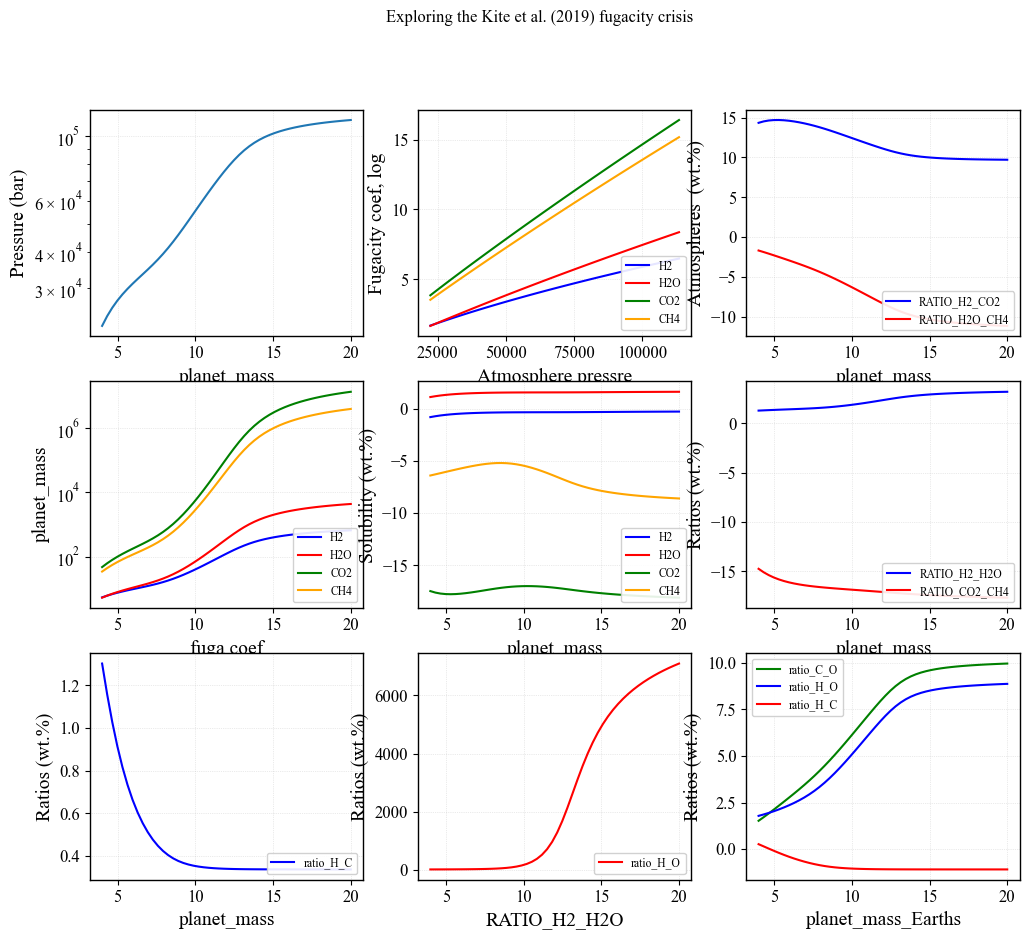

In [47]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

ax = axes[0, 0]
ax.plot(planet_mass_Earths, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(planet_mass_Earths, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacity_coefficientCH4, label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_yscale("log")
ax.set_xlabel("fuga coef")
ax.set_ylabel("planet_mass")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpCO2), label='CO2', color='green')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
ax.plot(pressure, np.log(fugacity_coefficientH2), label='H2', color='blue')
ax.plot(pressure, np.log(fugacity_coefficientH2O), label='H2O', color='red')
ax.plot(pressure, np.log(fugacity_coefficientCO2), label='CO2', color='green')
ax.plot(pressure, np.log(fugacity_coefficientCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Atmosphere pressre")
ax.set_ylabel(r"Fugacity coef, log")

ax = axes[0, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(RATIO_H2_CO2), label='RATIO_H2_CO2', color='blue')
ax.plot(planet_mass_Earths, np.log(RATIO_H2O_CH4), label='RATIO_H2O_CH4', color='red')
ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Atmospheres  (wt.%)")

ax = axes[1, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(RATIO_H2_H2O), label='RATIO_H2_H2O', color='blue')
ax.plot(planet_mass_Earths, np.log(RATIO_CO2_CH4), label='RATIO_CO2_CH4', color='red')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 0]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, ratio_H_C, color='blue', label='ratio_H_C')
ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 1]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, ratio_H_O, color='red', label='ratio_H_O')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"RATIO_H2_H2O")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(ratio_C_O), color='green', label='ratio_C_O')
ax.plot(planet_mass_Earths, np.log(ratio_H_O), color='blue', label='ratio_H_O')
ax.plot(planet_mass_Earths, np.log(ratio_H_C), color='red', label='ratio_H_C')


ax.legend(fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Ratios (wt.%)")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

In [50]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd

# ===========================================================
# MASTER NATURE-STYLE LAYOUT
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 14
    plt.rcParams["xtick.labelsize"]    = 12
    plt.rcParams["ytick.labelsize"]    = 12
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.5
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)

def apply_secondary_gpa_axis(ax):
    def bar_to_gpa(x): return x * 1e-4
    def gpa_to_bar(x): return x * 1e4
    ax2 = ax.secondary_yaxis('right', functions=(bar_to_gpa, gpa_to_bar))
    ax2.set_ylabel("Surface pressure  [GPa]")
    ax2.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax2.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    return ax2

def apply_master_layout(fig, ax, title):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    fig.suptitle(title, fontsize=20, ha="center", x=0.52, y=0.95)
    ax.legend(
        frameon=True,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5)
    )

def apply_bachelor_layout(fig, ax, title):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    fig.suptitle(title, fontsize=20, ha="center", x=0.52, y=0.95)
    ax.legend(
        frameon=True,
        loc="upper left",
        bbox_to_anchor=(0.01, 0.98)
    )

# ===========================================================
# EXTRACT FROM YOUR DATAFRAMES
# ===========================================================
output_df = A_FINAL_TEST_MASS_REAL.to_dataframes()

planet_mass_Earths = output_df["planet"]["planet_mass"]

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

# Dissolved species
dissolved_wtpH2  = output_df["H2_g"]["dissolved_ppmw"]  * 1e-4
dissolved_wtpH2O = output_df["H2O_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpCO  = output_df["CO_g"]["dissolved_ppmw"]  * 1e-4
dissolved_wtpCO2 = output_df["CO2_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpCH4 = output_df["CH4_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpHCN = output_df["CHN_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpNH3 = output_df["H3N_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpN2 = output_df["N2_g"]["dissolved_ppmw"] * 1e-4

# Atmospheric elemental abundances
element_H_red = output_df["element_H"]["atmosphere_moles"] 
element_O_red = output_df["element_O"]["atmosphere_moles"]
element_C_red = output_df["element_C"]["atmosphere_moles"]

element_H_abund = output_df["element_H"]["atmosphere_moles"] 
element_C_abund = output_df["element_C"]["atmosphere_moles"] 
element_O_abund = output_df["element_O"]["atmosphere_moles"] 
element_N_abund = output_df["element_N"]["atmosphere_moles"] 

ratio_H_C = element_H / element_C
ratio_H_O = element_H / element_O
ratio_C_O = element_C / element_O
ratio_C_N = element_C / element_N
ratio_H_N = element_H / element_N

element_H_rel = output_df["element_H"]["atmosphere_moles"] / output_df["element_H"]["total_moles"]
element_O_rel = output_df["element_O"]["atmosphere_moles"] / output_df["element_O"]["total_moles"]
element_C_rel = output_df["element_C"]["atmosphere_moles"] / output_df["element_C"]["total_moles"]
element_N_rel = output_df["element_N"]["atmosphere_moles"] / output_df["element_N"]["total_moles"]

X_TICKS = np.arange(4, 21, 1)

def set_x_ticks(ax):
    ax.set_xticks(X_TICKS)
    ax.set_xlim(4, 20)

In [52]:
planet_mass_Earths = np.linspace(4, 20, number_of_realisations)

<>:23: SyntaxWarning: invalid escape sequence '\o'
<>:23: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/3044464169.py:23: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


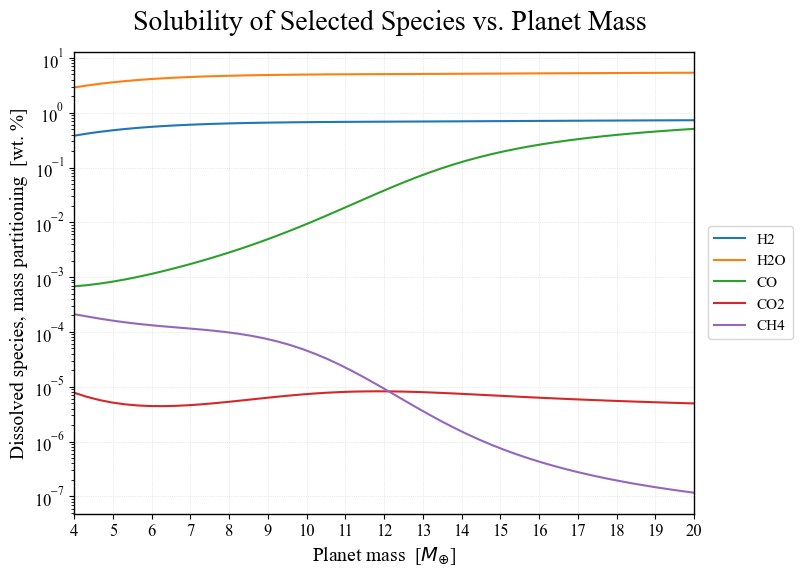

In [43]:
# ===========================================================
# FIGURE 1 — Solubility of species vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, dissolved_wtpH2,  label="H2")
ax.plot(planet_mass_Earths, dissolved_wtpH2O, label="H2O")
ax.plot(planet_mass_Earths, dissolved_wtpCO,  label="CO")
ax.plot(planet_mass_Earths, dissolved_wtpCO2, label="CO2")
ax.plot(planet_mass_Earths, dissolved_wtpCH4, label="CH4")

set_x_ticks(ax)
ax.set_yscale("log")
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
fig.suptitle("Solubility of Selected Species vs. Planet Mass", fontsize=20, ha="center", x=0.52, y=0.95)
ax.legend(
    frameon=True,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("Dissolved species, mass partitioning  [wt. %]")

plt.show()



<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/2103969664.py:21: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


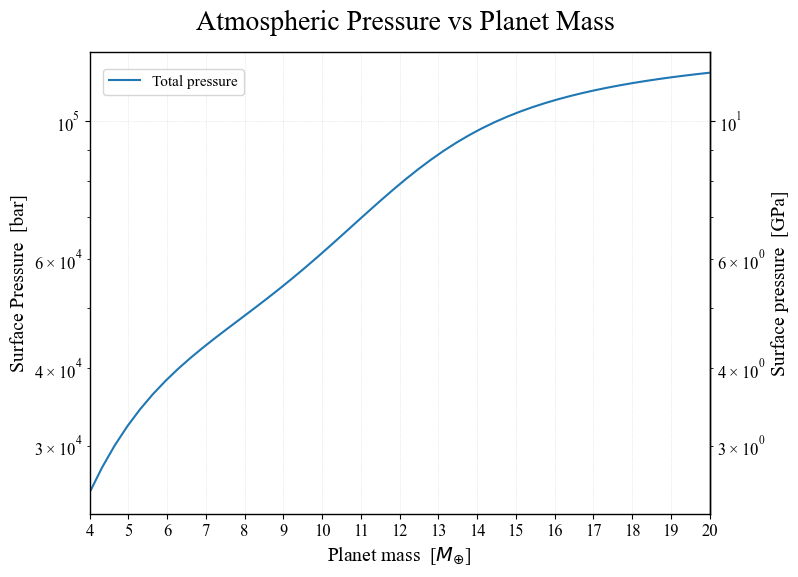

In [44]:
# ===========================================================
# FIGURE 2 — Atmospheric pressure vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, pressure, label="Total pressure")

set_x_ticks(ax)
apply_secondary_gpa_axis(ax)
set_x_ticks(ax)
ax.set_yscale("log")
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
fig.suptitle("Atmospheric Pressure vs Planet Mass", fontsize=20, ha="center", x=0.52, y=0.95)
ax.legend(
    frameon=True,
    loc="upper left",
    bbox_to_anchor=(0.01, 0.98)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("Surface Pressure  [bar]")

plt.show()



<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/4059550356.py:21: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


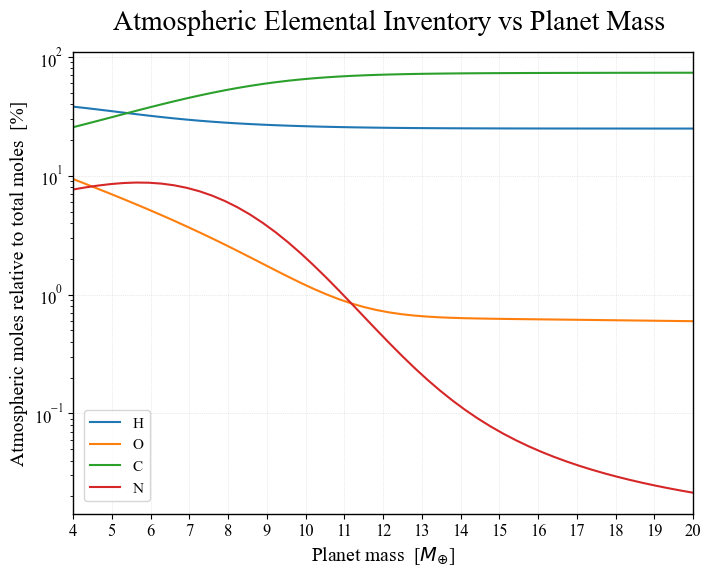

In [45]:
# ===========================================================
# FIGURE 3 — Elemental atmospheric abundances vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, element_H, label="H")
ax.plot(planet_mass_Earths, element_O, label="O")
ax.plot(planet_mass_Earths, element_C, label="C")
ax.plot(planet_mass_Earths, element_N, label="N")
set_x_ticks(ax)
ax.set_yscale("log")
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
fig.suptitle("Atmospheric Elemental Inventory vs Planet Mass", fontsize=20, ha="center", x=0.52, y=0.95)
ax.legend(
    frameon=True,
    loc="lower left",
    bbox_to_anchor=(0.005, 0.01)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("Atmospheric moles relative to total moles  [%]")

plt.show()

<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/80248842.py:18: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


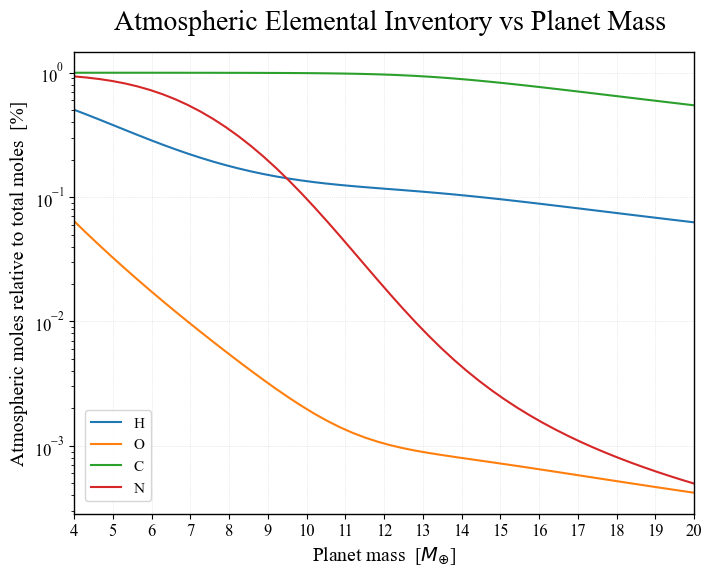

In [46]:
# ===========================================================
# FIGURE 3 — Elemental atmospheric abundances vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, element_H_rel, label="H")
ax.plot(planet_mass_Earths, element_O_rel, label="O")
ax.plot(planet_mass_Earths, element_C_rel, label="C")
ax.plot(planet_mass_Earths, element_N_rel, label="N")
set_x_ticks(ax)
apply_master_layout(fig, ax, "Atmospheric Elemental Inventory vs Planet Mass")
ax.legend(
    frameon=True,
    loc="lower left",
    bbox_to_anchor=(0.005, 0.01)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("Atmospheric moles relative to total moles  [%]")

plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\o'
<>:15: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/108895680.py:15: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


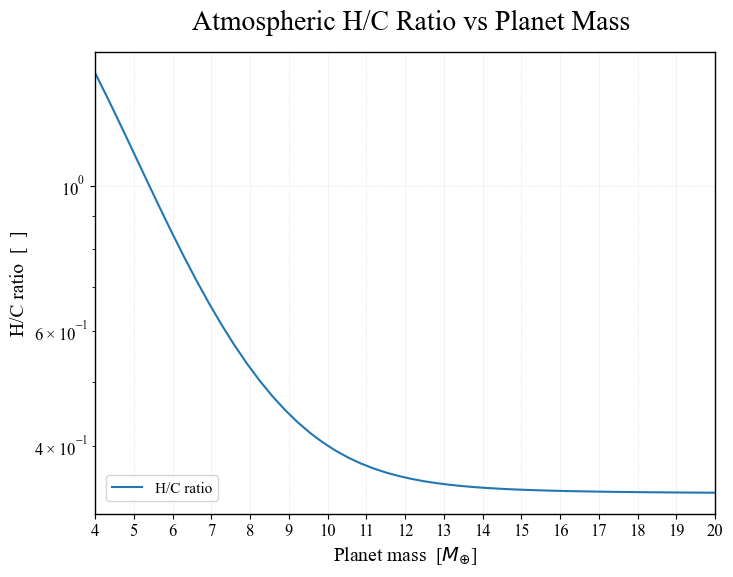

In [47]:
# ===========================================================
# FIGURE 4 — H/C ratio vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, ratio_H_C , label="H/C ratio")
set_x_ticks(ax)
apply_master_layout(fig, ax, "Atmospheric H/C Ratio vs Planet Mass")
ax.legend(
    frameon=True,
    loc="lower left",
    bbox_to_anchor=(0.005, 0.01)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("H/C ratio  [  ]")

plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\o'
<>:15: SyntaxWarning: invalid escape sequence '\o'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89795/1111350188.py:15: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel("Planet mass  [$M_{\oplus}$]")


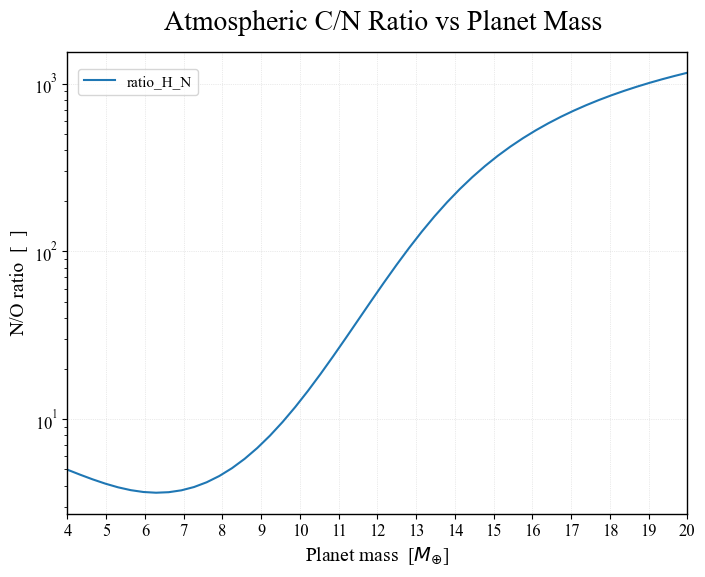

In [53]:
# ===========================================================
# FIGURE 4 — H/C ratio vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, ratio_H_N, label="ratio_H_N")
set_x_ticks(ax)
apply_master_layout(fig, ax, "Atmospheric C/N Ratio vs Planet Mass")
ax.legend(
    frameon=True,
    loc="upper left",
    bbox_to_anchor=(0.005, 0.98)
)
ax.set_xlabel("Planet mass  [$M_{\oplus}$]")
ax.set_ylabel("N/O ratio  [  ]")

plt.show()

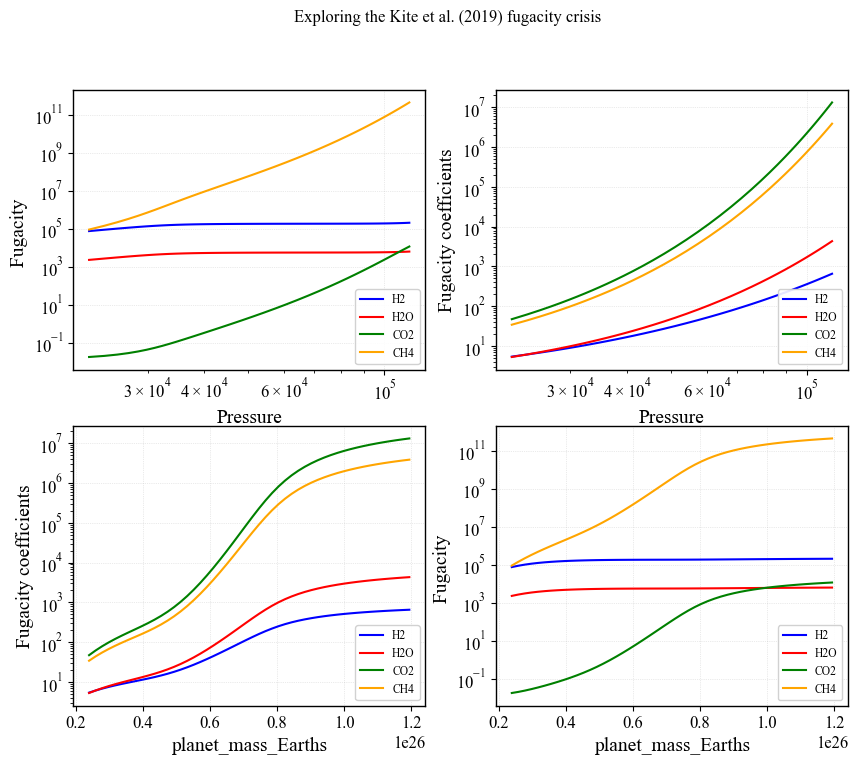

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(pressure, fugacityH2, label='H2', color='blue')
ax.plot(pressure, fugacityH2O, label='H2O', color='red')
ax.plot(pressure, fugacityCO2, label='CO2', color='green')
ax.plot(pressure, fugacityCH4, label='CH4', color='orange')
ax.set_yscale("log")
ax.set_xscale("log")
ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Pressure")
ax.set_ylabel("Fugacity ")


ax = axes[0, 1]
ax.plot(pressure, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(pressure, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(pressure, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(pressure, fugacity_coefficientCH4, label='CH4', color='orange')
ax.set_yscale("log")
ax.set_xscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Pressure")
ax.set_ylabel("Fugacity coefficients")

ax = axes[1, 1]
ax.plot(planet_mass_Earths, fugacityH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacityH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacityCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacityCH4, label='CH4', color='orange')
ax.set_yscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Fugacity ")

ax = axes[1, 0]
ax.plot(planet_mass_Earths, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacity_coefficientCH4, label='CH4', color='orange')
ax.set_yscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Fugacity coefficients")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

## Surface temparature

Planet mass varies from 4 to 9 MEarth, surface radius is fixed at 1.76 REarth

In [161]:

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

temps =  np.linspace(2500, 3500, number_of_realisations)

# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.58)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [111]:
sub_neptune = Planet(
    surface_temperature=temps,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [112]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("A_FINAL_TEST_TEMP_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("A_FINAL_TEST_TEMP_IDEAL")

[14:26:45 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[14:26:45 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:26:45 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[14:26:45 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[14:26:45 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[14:26:45 - atmodeller.classes             - INFO     ] - Solver steps (max) = 38
[14:26:45 - atmodeller.output              - INFO     ] - Writing output to excel
[14:26:45 - a

In [113]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
A_FINAL_TEST_TEMP_REAL = model_real_varyMp_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_TEMP_REAL.to_excel("A_FINAL_TEST_TEMP_REAL")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_TEMP_REAL.to_pickle("A_FINAL_TEST_TEMP_REAL")

[14:26:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[14:26:46 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:26:46 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[14:26:46 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[14:26:46 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[14:26:46 - atmodeller.classes             - INFO     ] - Solver steps (max) = 14
[14:26:46 - atmodeller.output              - INFO    

In [97]:

output_df = A_FINAL_TEST_TEMP_REAL.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

fugacityH2 = output_df["H2_g"]["fugacity"]
fugacityH2O = output_df["H2O_g"]["fugacity"]
fugacityCO2 = output_df["CO2_g"]["fugacity"]
fugacityCH4 = output_df["CH4_g"]["fugacity"]



dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["dissolved_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["dissolved_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%


molesCH4 = output_df["CH4_g"]["atmosphere_moles"] / output_df["CH4_g"]["total_moles"]


H2_1 = fugacityH2[0]
H2_2 = fugacityH2[49]

H2O_1 = fugacityH2O[0]
H2O_2 = fugacityH2O[49]

CO2_1 = fugacityCO2[0]
CO2_2 = fugacityCO2[49]

CH4_1 = fugacityCH4[0]
CH4_2 = fugacityCH4[49]

K_1 = (CH4_1 * H2O_1**2) / (CO2_1 * H2_1**4)
K_2 = (CH4_2 * H2O_2**2) / (CO2_2 * H2_2**4)

print(K_1 - K_2)


NameError: name 'A_FINAL_TEST_TEMP_REAL' is not defined

NameError: name 'temps' is not defined

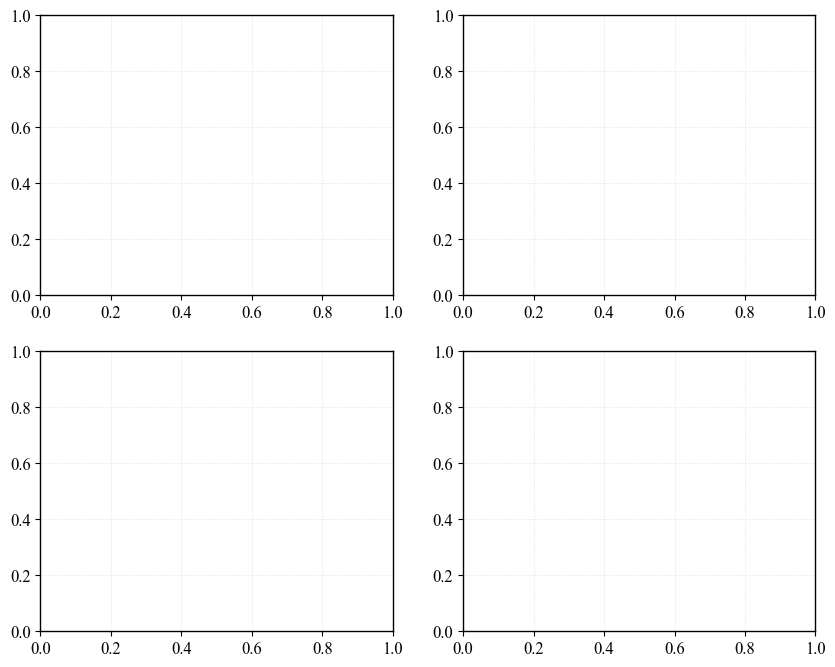

In [98]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(temps, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"Temp")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(temps, np.log(fugacity_coefficientH2), label='H2', color='blue')
ax.plot(temps, np.log(fugacity_coefficientH2O), label='H2O', color='red')
ax.plot(temps, np.log(fugacity_coefficientCO2), label='CO2', color='green')
ax.plot(temps, np.log(fugacity_coefficientCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel("temp")
ax.set_ylabel("fuga coef, log")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(temps, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(temps, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.plot(temps, np.log(dissolved_wtpCO2), label='CO2', color='green')
ax.plot(temps, np.log(dissolved_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Total volatile mass added (wt.% of core mass)")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
ax.plot(temps, np.log(fugacityH2), label='H2', color='blue')
ax.plot(temps, np.log(fugacityH2O), label='H2O', color='red')
ax.plot(temps, np.log(fugacityCO2), label='CO2', color='green')
ax.plot(temps, np.log(fugacityCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel("temp ")
ax.set_ylabel("fuga, log")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()